# Planta Física: Genetic algorithms

Group MA2015.202, Team 08

- Aldo Tolentino Luna (A01668465)
- Emilio Estrada Pérez (A01770665)
- Juan Diego Rodríguez Espinoza (A01667431)

| Role | Research (M1) | Development (M2) | Final (M3) |
|------|---------------|------------------|------------|
| Driver | Juan Diego | Emilio Estrada | Aldo Tolentino |
| Reviewer | Emilio Estrada | Aldo Tolentino | Juan Diego |
| Verifier | Aldo Tolentino | Juan Diego | Emilio Estrada |


Data: Recorded water demands during March 2025 

GitHub: https://github.com/Monknow/reto-planta-fisica

**Notebook map.** Research (M1): Sections 1-2. The genetic algorithm: Sections 3-8. Development (M2): Section 9. Final (M3): Sections 10-11.

## 1. Problem Definition

The _Planta Física_ needs to allocate treated water to four buildings (Aulas I, Biblioteca, CEDETEC, Aulas II) to reduce the potable water consumed. If we don't provide enough treated water to meet each building's demands, then the remaining demand is fulfilled by potable water.

The total water demand of each building during March 2025 (monthly totals from the records) is:

- Aulas 1 = 847 m$^3$
- Biblioteca = 462 m$^3$
- Cedetec = 284.21 m$^3$
- Aulas 2 = 683 m$^3$

We suppose the maximum treated-water capacity for March 2025 is 1 410 m$^3$ (a monthly total).

**Note:** The monthly capacity is a teaching assumption; it is not a partner-confirmed capacity.

All quantities in this notebook ($D_i$, $\sum_i D_i = 2276.21$ m$^3$, $C$, $T$, $P$ and $E$) are monthly totals for March 2025, so the model applies only to this monthly exercise.

Each building has a reuse limit which represents the maximum percentage of the building's monthly demand that can be covered with treated water.

- Aulas 1 = 80%
- Biblioteca = 80%
- Cedetec = 60%
- Aulas 2 = 80%

**Note:** The reuse limits are teaching assumptions.

We can vary the reuse percentage within their limit. To describe each reuse percentage, we'll encode them together in a chromosome $k=(k_1,k_2,k_3,k_4)$ Using integers: 

- $k_1,k_2,k_4\in\{0,\ldots,80\}$ 
- $k_3\in\{0,\ldots,60\}$. 

Where $x_i=k_i/100$, so each gene is a reuse percentage in steps of one percentage point. For example, gene 60 represents 60% reuse. This means we have $81\times81\times61\times81=32\,417\,901$ combinations which we'll navigate using the genetic algorithm to find the best combination.

The next table summarizes each building's details:


| Building   | Demand $D_i$ ($m^3$) | Domain of $k_i$    | Maximum reuse |
|:-----------|---------------------:|:------------------:|--------------:|
| Aulas 1    | 847.00               | $\{0,\ldots,80\}$  | 80%           |
| Biblioteca | 462.00               | $\{0,\ldots,80\}$  | 80%           |
| Cedetec    | 284.21               | $\{0,\ldots,60\}$  | 60%           |
| Aulas 2    | 683.00               | $\{0,\ldots,80\}$  | 80%           |

In [1]:
import matplotlib.pyplot as plt
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, monthly totals, March 2025
LIMITS = np.array([80, 80, 60, 80])  # integer percentage levels
SCALE = 100  # fractions = levels / SCALE
CAPACITY = 1410.0  # m3 per month (March 2025); teaching assumption, not confirmed plant capacity

## 2. The Fitness Function

Our decision variable is the reuse percentage on each building. To evaluate each combination, we'll need to define a fitness function that determines the efficiency of each chromosome. To do so, we'll define the following values:

**Treated Water:** The amount of treated water the system used, which is just the sum of the treated water for each building.

$$\text{Treated water: } T_i = D_i\frac{k_i}{100}, \qquad T= \sum_i T_i = \frac{1}{100} \sum_i D_i k_i$$

**Potable Water:** The amount of potable water we had to inject in the system to satisfy demand. It is the total demand minus the treated water the system was able to use.

$$\text{Potable water: } P_i = D_i - T_i, \qquad P=\sum_i P_i = \sum_iD_i-T$$

**Excess capacity:** The system cannot provide treated water ($T$) beyond its established capacity ($C$). Once $T$ is greater than $C$, the system becomes unfeasiable since we are using treated water we don't even have. The excess capacity represents the amount of *unavailable* treated water the system is trying to use. 

$$\text{Excess capacity: } E=\max(0,T-C)$$

In other words, once the Excess capacity is greater than zero, the system is unfesiable.

With that said, our goal is to minimize $P$ (the amount of potable water the system requires), subject to the gene domains and $T\le C$ (using the available treated water). 

To get a better sense of the efficiency of the system, instead of directly minimizing $P$, we'll minimize $F= \frac{P}{\sum D_i}$, which represents the ratio of the demand that's satisified by potable water. Our fitness function is then F where **lower fitness is better.**

Note that, if we use the current $F$ as the fitness function, we could cheat the system by ignoring the system's capacity, setting $P$ to zero and $T$ to the maximum, resulting in a perfect $F = 0$. To avoid this, whenever the system is unfeasible we set  $F=1+\frac{E}{C}$. This way, a feasible candidate has $F\le1$; an unfeasible candidate has $F>1$

We use a numerical tolerance of $10^{-8}$ m$^3$.

### Calculations by Hand

Before running the code, let's calculate by hand three candidates. For each one we first compute the treated and potable water building by building, $T_i = D_i\frac{k_i}{100}$ and $P_i = D_i - T_i$, check that $T_i + P_i = D_i$, and then add the rows to get $T$ and $P$. All volumes are monthly totals for March 2025, in m$^3$.

$$\sum_i D_i = D_1+D_2+D_3+D_4 = 847.00+462.00+284.21+683.00 = 2276.21\ \text{m}^3$$

1. Constant reuse: $k=(60,60,60,60)$

Every $k_i=60$, therefore $x_i = \frac{60}{100} = 0.6$. The four products are:

- $T_1 = 847 \times 0.6 = 508.200$ m$^3$
- $T_2 = 462 \times 0.6 = 277.200$ m$^3$
- $T_3 = 284.21 \times 0.6 = 170.526$ m$^3$
- $T_4 = 683 \times 0.6 = 409.800$ m$^3$

| Building | $D_i$ (m$^3$) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m$^3$) | $P_i=D_i-T_i$ (m$^3$) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 60 | 0.6 | 847 $\times$ 0.6 = 508.200 | 847.00 - 508.200 = 338.800 | 508.200 + 338.800 = 847.00 OK |
| Biblioteca | 462.00 | 60 | 0.6 | 462 $\times$ 0.6 = 277.200 | 462.00 - 277.200 = 184.800 | 277.200 + 184.800 = 462.00 OK |
| Cedetec | 284.21 | 60 | 0.6 | 284.21 $\times$ 0.6 = 170.526 | 284.21 - 170.526 = 113.684 | 170.526 + 113.684 = 284.21 OK |
| Aulas 2 | 683.00 | 60 | 0.6 | 683 $\times$ 0.6 = 409.800 | 683.00 - 409.800 = 273.200 | 409.800 + 273.200 = 683.00 OK |
| **Total** | **2276.21** | | | **1365.726** | **910.484** | 1365.726 + 910.484 = 2276.21 OK |

$$
\begin{aligned}
& T = \sum_i T_i = 508.200+277.200+170.526+409.800 = 1365.726\ \text{m}^3 \\
& P = \sum_i P_i = 338.800+184.800+113.684+273.200 = 910.484\ \text{m}^3 \quad (= 2276.21-1365.726) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1365.726-1410 = -44.274 \le 0 \\
& \text{Then } E = \max(0,\ -44.274) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{910.484}{2276.21} = 0.4
\end{aligned}
$$

2. Zero reuse: $k = (0, 0, 0, 0)$

Every $k_i=0$, therefore $x_i = \frac{0}{100} = 0$, so every product is zero ($847 \times 0 = 462 \times 0 = 284.21 \times 0 = 683 \times 0 = 0$ m$^3$) and each building is supplied only with potable water.

| Building | $D_i$ (m$^3$) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m$^3$) | $P_i=D_i-T_i$ (m$^3$) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 0 | 0.0 | 847 $\times$ 0.0 = 0.000 | 847.00 - 0.000 = 847.000 | 0.000 + 847.000 = 847.00 OK |
| Biblioteca | 462.00 | 0 | 0.0 | 462 $\times$ 0.0 = 0.000 | 462.00 - 0.000 = 462.000 | 0.000 + 462.000 = 462.00 OK |
| Cedetec | 284.21 | 0 | 0.0 | 284.21 $\times$ 0.0 = 0.000 | 284.21 - 0.000 = 284.210 | 0.000 + 284.210 = 284.21 OK |
| Aulas 2 | 683.00 | 0 | 0.0 | 683 $\times$ 0.0 = 0.000 | 683.00 - 0.000 = 683.000 | 0.000 + 683.000 = 683.00 OK |
| **Total** | **2276.21** | | | **0.000** | **2276.210** | 0.000 + 2276.210 = 2276.21 OK |

$$
\begin{aligned}
& T = \sum_i T_i = 0\ \text{m}^3 \\
& P = \sum_i P_i = 2276.21-0 = 2276.21\ \text{m}^3 \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 0-1410 = -1410 \le 0 \\
& \text{Then } E = \max(0,\ -1410) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{2276.21}{2276.21} = 1.0
\end{aligned}
$$

3. Maximum levels in each domain: $k = (80, 80, 60, 80)$

Here $k_i=80$ for $i\in\{1,2,4\}$ and $k_3=60$, therefore $x_1=x_2=x_4=0.8$ and $x_3=0.6$. The four products are:

- $T_1 = 847 \times 0.8 = 677.600$ m$^3$
- $T_2 = 462 \times 0.8 = 369.600$ m$^3$
- $T_3 = 284.21 \times 0.6 = 170.526$ m$^3$
- $T_4 = 683 \times 0.8 = 546.400$ m$^3$

| Building | $D_i$ (m$^3$) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m$^3$) | $P_i=D_i-T_i$ (m$^3$) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 80 | 0.8 | 847 $\times$ 0.8 = 677.600 | 847.00 - 677.600 = 169.400 | 677.600 + 169.400 = 847.00 OK |
| Biblioteca | 462.00 | 80 | 0.8 | 462 $\times$ 0.8 = 369.600 | 462.00 - 369.600 = 92.400 | 369.600 + 92.400 = 462.00 OK |
| Cedetec | 284.21 | 60 | 0.6 | 284.21 $\times$ 0.6 = 170.526 | 284.21 - 170.526 = 113.684 | 170.526 + 113.684 = 284.21 OK |
| Aulas 2 | 683.00 | 80 | 0.8 | 683 $\times$ 0.8 = 546.400 | 683.00 - 546.400 = 136.600 | 546.400 + 136.600 = 683.00 OK |
| **Total** | **2276.21** | | | **1764.126** | **512.084** | 1764.126 + 512.084 = 2276.21 OK |

$$
\begin{aligned}
& T = \sum_i T_i = 677.600+369.600+170.526+546.400 = 1764.126\ \text{m}^3 \\
& P = \sum_i P_i = 169.400+92.400+113.684+136.600 = 512.084\ \text{m}^3 \quad (= 2276.21-1764.126) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1764.126-1410 = 354.126 > 0 \\
& \text{Then } E = \max(0,\ 354.126) = 354.126\ \text{m}^3 \\ \\

& \text{Since it is not feasible } (T>C), \text{ let's calculate the fitness function as:} \\ \\

& F = 1+\frac{E}{C} = 1+\frac{354.126}{1410} = 1.25115319
\end{aligned}
$$

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)

    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")

    treated = float(np.sum(DEMAND * genes / SCALE))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m^3

    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY

    return {
        "treated": treated,
        "potable": potable,
        "excess": excess,
        "feasible": feasible,
        "fitness": fitness,
    }

In [3]:
cases = [np.zeros(4, dtype=int), np.array([60, 60, 60, 60]), LIMITS.copy()]

for genes in cases:
    print(genes, evaluate(genes))

assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[60 60 60 60] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[80 80 60 80] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


We compare our manual values from the previous section with the output of `evaluate`. Volumes are rounded to 3 decimals (m$^3$) and $F$ to 8 decimals. The difference column is $|\text{manual} - \text{evaluator}|$ computed with the unrounded evaluator output.

| Case $k$ | Metric | Manual value | Evaluator value | Difference |
|:--|:--|--:|--:|--:|
| $(60,60,60,60)$ | `treated` $T$ (m$^3$) | 1365.726 | 1365.726 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m$^3$) | 910.484 | 910.484 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m$^3$) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | equal |
| | `fitness` $F$ | 0.40000000 | 0.40000000 | $5.6\times10^{-17}$ |
| $(0,0,0,0)$ | `treated` $T$ (m$^3$) | 0.000 | 0.000 | 0 |
| | `potable` $P$ (m$^3$) | 2276.210 | 2276.210 | 0 |
| | `excess` $E$ (m$^3$) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | equal |
| | `fitness` $F$ | 1.00000000 | 1.00000000 | 0 |
| $(80,80,60,80)$ | `treated` $T$ (m$^3$) | 1764.126 | 1764.126 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m$^3$) | 512.084 | 512.084 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m$^3$) | 354.126 | 354.126 | $2.3\times10^{-13}$ |
| | `feasible` | False | False | equal |
| | `fitness` $F$ | 1.25115319 | 1.25115319 | $1.5\times10^{-9}$ |

All five keys agree for the three cases. The nonzero differences of order $10^{-13}$ come from floating-point representation in the code, and the $1.5\times10^{-9}$ in $F$ for $(80,80,60,80)$ comes from rounding our manual value to 8 decimals (the evaluator gives $1.2511531914\ldots$). None of them come from the model.

We also see that it isn't feasible to set the reuse percentage to the maximum, so we'll have to make sacrifices about which genes to use. From our manual tests, the $[60, 60, 60, 60]$ chromosome had the best fitness.

## 3. We generate a population

We define the population a the list of candidates. We sample each gene within its domain, including both endpoints. Note that sampling does not guarantee a feasible solution. However, we hope the fitness punishment for unfeasible solutions will rule out those chromosomes.

In [4]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)


rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[ 7 62 39 35] 0.694394673602172
[35 69  5 56] 0.5554362295218807
[16  7 32 79] 0.6492515189723268
[59 61 43 63] 0.41391598314742495


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent. Note that the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. 

See that we return a copy to protect the original.

In [5]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()


parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[35 69  5 56] [35 69  5 56]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and join the beginning of one parent with the end of the other. Note that each gene keeps its position, so the first gene always describes Aulas 1, the second Biblioteca, and so on. For parents $(60,60,60,60)$ and $(80,20,40,30)$ with cut 2, we obtain $(60,60,40,30)$.

Since every gene comes from a parent, the child always stays inside the gene domains. However, nothing guarantees it respects the capacity, so a child can be unfeasible and we let $F$ punish it. Also note that if both tournaments return the same individual, the child is just a copy of that parent.

This is the supplied **baseline** crossover. In Section 9 (Development) we keep it unchanged and compare it with a team variant.

In [6]:
def crossover(
    parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))


child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[35 69  5 56] {'treated': 1011.9205000000001, 'potable': 1264.2894999999999, 'excess': 0.0, 'feasible': True, 'fitness': 0.5554362295218807}


## 6. We introduce variation through mutation

Crossover only recombines genes that already exist in the population, so we need mutation to try new values. We apply the probability to **each gene** instead of the whole chromosome, and a selected gene moves one valid level (one percentage point) up or down. At zero it can only go up, and at its maximum it can only go down.

With $p=0.25$ and four genes, we expect one mutated gene per child on average, but not exactly one: some children won't mutate at all and others will mutate two or more. Note that mutation can improve or worsen $F$, and it can even turn a feasible child into an unfeasible one.

In [7]:
def mutate(
    child: np.ndarray, probability: float, rng: np.random.Generator
) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result


mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[35 69  5 56] [35 69  5 57] {'treated': 1018.7505000000001, 'potable': 1257.4595, 'excess': 0.0, 'feasible': True, 'fitness': 0.552435627644198}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children, so the population size stays constant. This is called elitism: the best fitness can never get worse from one generation to the next. Note that this doesn't mean we found the optimum, only that we don't lose the best candidate we've seen.

See that we copy the elite and only mutate the children, so mutating a child never changes its parent or the elite. If no child beats the elite, the best fitness stays the same, which is what we see in the demo below.

In [8]:
def next_generation(
    population: list,
    probability: float,
    rng: np.random.Generator,
    crossover_fn=crossover,
) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_fn(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement


replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.41391598314742495
0.41391598314742495


## 8. We complete the cycle

We initialize the population and then repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the best $F$ at initialization and after each generation, so 20 generations give us 21 values. Don't expect an improvement at every step: because of elitism the curve never goes up, but it can stay flat for many generations.

In [9]:
def run_ga(
    population_size: int = 20,
    generations: int = 20,
    mutation_probability: float = 0.25,
    seed: int = 42,
    crossover_fn=crossover,
) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng, crossover_fn)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Development: we compare three versions

We preserve the supplied baseline and add two team changes, one at a time, so each comparison isolates a single change:

| Version | Gene domains | $x_i$ | Crossover | Compared with |
|:--|:--|:--|:--|:--|
| **V1** (supplied baseline) | $\{0,\ldots,8\}$, Cedetec $\{0,\ldots,6\}$ | $k_i/10$ | one-point | n/a |
| **V2** | $\{0,\ldots,80\}$, Cedetec $\{0,\ldots,60\}$ | $k_i/100$ | one-point | V1: only the resolution changes |
| **V3** | $\{0,\ldots,80\}$, Cedetec $\{0,\ldots,60\}$ | $k_i/100$ | **midpoint** | V2: only the crossover operator changes |

Selection (Section 4), mutation (Section 6) and elitism (Section 7) are the same code in all three versions. Note that mutation moves a gene by one level, so in V1 a mutation step is 10 percentage points and in V2 and V3 it is 1 percentage point; this is part of the resolution change, not a change to the operator. The supplied one-point `crossover` is still the default of `next_generation` and `run_ga`. The Final (Section 10) uses V3.

### 9.1 Limitations and hypotheses

**V1 to V2: resolution.** *Limitation:* with steps of 10%, the treated water $T$ can only take a few values, and only one chromosome of the 5 103 gets within 0.02 m$^3$ of the capacity. *Hypothesis:* with steps of 1% there are many more chromosomes close to $T=C$ (32 417 901 combinations), so the GA should end closer to the capacity, with a lower $F$. *Risk:* the search space is more than 6 000 times larger, and mutation moves only 1 percentage point at a time.

**V2 to V3: crossover.** *Limitation:* one-point crossover only *copies* genes, so every gene of the child is a value that one of the parents already had. With 81 levels per gene, the only way to reach new values is mutation, one percentage point at a time. With four genes there are also only three possible cuts. *Change:* we interpolate linearly between both parents and keep the half value of each gene, rounding to the nearest integer (a .5 goes up):

$$c_i = \operatorname{round}\left(\frac{a_i + b_i}{2}\right) = \left\lfloor\frac{a_i+b_i+1}{2}\right\rfloor$$

For parents $(60,60,60,60)$ and $(80,20,40,31)$ we obtain $(70,40,50,46)$, where $45.5 \to 46$. The midpoint of two values in a domain is in that domain, so the child always respects the gene limits; the capacity is still handled by $F$.

*Hypothesis:* for a feasible candidate, $F = 1 - T/\sum_i D_i$, so the best solutions lie just below the boundary $T = C$. Since $T$ is linear in the genes, the child's treated water is approximately the average of its parents': $T(c) \approx \frac{T(a)+T(b)}{2}$. If one parent is below the capacity and the other above it, the child falls between them, closer to the boundary. We therefore expect V3 to reach a lower $F$ than V2 with seed 42. *Risk:* averaging pulls every child towards the middle of its parents, so the population can lose diversity quickly (premature convergence).

In [10]:
def crossover_midpoint(
    parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    """Create one child from the gene-wise midpoint of both parents, rounded half up."""
    # rng is kept so both operators share the same signature; the midpoint is deterministic.
    return (parent_a + parent_b + 1) // 2


example_a, example_b = np.array([60, 60, 60, 60]), np.array([80, 20, 40, 31])
example_child = crossover_midpoint(example_a, example_b, rng_demo)
print(example_a, "+", example_b, "->", example_child)
assert np.array_equal(example_child, [70, 40, 50, 46])  # 45.5 rounds up to 46
assert np.all(example_child >= 0) and np.all(example_child <= LIMITS)

[60 60 60 60] + [80 20 40 31] -> [70 40 50 46]


### 9.2 We run the three versions under the same conditions

All three runs use the same data, capacity, tournament selection, mutation ($p_m=0.25$), elitism, population (20), generations (20) and seed (42). `resolution` temporarily switches the gene domains and the scale used by every function, and restores them afterwards, so V1 runs exactly the supplied code. The assertions check that V1 reproduces the supplied baseline result $(7,4,3,8)$ and that V2 is exactly what `run_ga` gives with its default operators.

In [11]:
from contextlib import contextmanager


@contextmanager
def resolution(limits, scale):
    """Temporarily change the gene domains and scale used by every GA function."""
    global LIMITS, SCALE
    saved = LIMITS, SCALE
    LIMITS, SCALE = np.array(limits), scale
    try:
        yield
    finally:
        LIMITS, SCALE = saved


VERSIONS = {
    "V1: 0-8, one-point": dict(limits=[8, 8, 6, 8], scale=10, crossover_fn=crossover),
    "V2: 0-80, one-point": dict(limits=[80, 80, 60, 80], scale=100, crossover_fn=crossover),
    "V3: 0-80, midpoint": dict(limits=[80, 80, 60, 80], scale=100, crossover_fn=crossover_midpoint),
}


def run_version(name: str, **config) -> dict:
    """Run run_ga with the gene domains, scale and crossover of one version."""
    version = VERSIONS[name]
    with resolution(version["limits"], version["scale"]):
        result = run_ga(**config, crossover_fn=version["crossover_fn"])
    result["fractions"] = result["genes"] / version["scale"]
    return result


DEV_CONFIG = {"population_size": 20, "generations": 20, "mutation_probability": 0.25, "seed": 42}
dev_results = {name: run_version(name, **DEV_CONFIG) for name in VERSIONS}

for name, result in dev_results.items():
    metrics = result["metrics"]
    treated_i = DEMAND * result["fractions"]
    print(f"{name}: genes = {result['genes']}")
    print(f"  {'Building':<11}{'k_i':>5}{'x_i':>6}{'T_i (m3)':>12}{'P_i (m3)':>12}")
    for b, k, x, t, d in zip(BUILDINGS, result["genes"], result["fractions"], treated_i, DEMAND):
        print(f"  {b:<11}{k:>5}{x:>6.2f}{t:>12.3f}{d - t:>12.3f}")
    print(f"  T = {metrics['treated']:.3f}  P = {metrics['potable']:.3f}  E = {metrics['excess']:.3f}"
          f"  feasible = {metrics['feasible']}  F = {metrics['fitness']:.8f}")
    print()

# V1 is exactly the supplied baseline, V2 is run_ga with its defaults, and the global domains are restored
np.testing.assert_array_equal(dev_results["V1: 0-8, one-point"]["genes"], [7, 4, 3, 8])
np.testing.assert_array_equal(dev_results["V2: 0-80, one-point"]["history"], run_ga(**DEV_CONFIG)["history"])
assert np.array_equal(LIMITS, [80, 80, 60, 80]) and SCALE == 100

V1: 0-8, one-point: genes = [7 4 3 8]


  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1        7  0.70     592.900     254.100
  BIBLIOTECA     4  0.40     184.800     277.200
  CEDETEC        3  0.30      85.263     198.947
  AULAS 2        8  0.80     546.400     136.600
  T = 1409.363  P = 866.847  E = 0.000  feasible = True  F = 0.38082910

V2: 0-80, one-point: genes = [59 59 32 80]
  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1       59  0.59     499.730     347.270
  BIBLIOTECA    59  0.59     272.580     189.420
  CEDETEC       32  0.32      90.947     193.263
  AULAS 2       80  0.80     546.400     136.600
  T = 1409.657  P = 866.553  E = 0.000  feasible = True  F = 0.38069985

V3: 0-80, midpoint: genes = [63 68 44 64]
  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1       63  0.63     533.610     313.390
  BIBLIOTECA    68  0.68     314.160     147.840
  CEDETEC       44  0.44     125.052     159.158
  AULAS 2       64  0.64     437.120     245.880
  T = 1409.942  P = 866.268  E = 

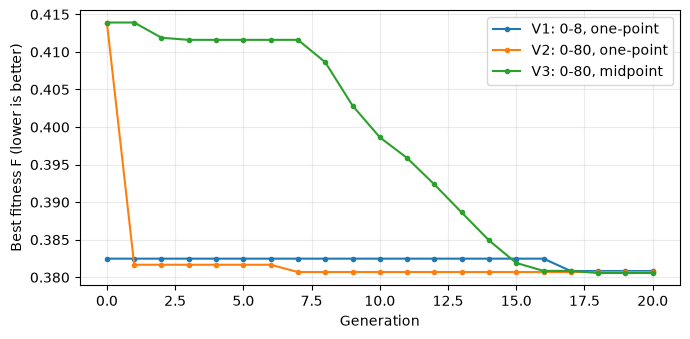

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, result in dev_results.items():
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=name)
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### 9.3 We compare the final chromosomes

| | V1: 0-8, one-point | V2: 0-80, one-point | V3: 0-80, midpoint |
|:--|--:|--:|--:|
| Final chromosome $k$ | $(7,4,3,8)$ | $(59,59,32,80)$ | $(63,68,44,64)$ |
| Reuse per building | 70%, 40%, 30%, 80% | 59%, 59%, 32%, 80% | 63%, 68%, 44%, 64% |
| $T_i$ Aulas 1 / Biblioteca / Cedetec / Aulas 2 (m$^3$) | 592.900 / 184.800 / 85.263 / 546.400 | 499.730 / 272.580 / 90.947 / 546.400 | 533.610 / 314.160 / 125.052 / 437.120 |
| $P_i$ Aulas 1 / Biblioteca / Cedetec / Aulas 2 (m$^3$) | 254.100 / 277.200 / 198.947 / 136.600 | 347.270 / 189.420 / 193.263 / 136.600 | 313.390 / 147.840 / 159.158 / 245.880 |
| Treated water $T$ (m$^3$) | 1409.363 | 1409.657 | 1409.942 |
| Potable water $P$ (m$^3$) | 866.847 | 866.553 | 866.268 |
| Unused capacity $C-T$ (m$^3$) | 0.637 | 0.343 | 0.058 |
| Excess capacity $E$ (m$^3$) | 0 | 0 | 0 |
| Feasible | Yes | Yes | Yes |
| Best fitness $F$ | 0.38082910 | 0.38069985 | 0.38057455 |

**Result with seed 42.** All three versions end feasible, and each one ends a little better than the previous one. V2 uses 0.294 m$^3$ less potable water than V1, and V3 uses 0.285 m$^3$ less than V2. In this run, both hypotheses hold.

## 10. Final: how the algorithm works and the effect of the mutation probability

### Algorithm version and corrections

- **Analyzed version: V3 from Development (Section 9).** Genes $k_i\in\{0,\ldots,80\}$ ($\{0,\ldots,60\}$ for Cedetec) with $x_i=k_i/100$, two-candidate tournament selection, **midpoint crossover** `crossover_midpoint`, per-gene $\pm1$ mutation, generational replacement with one elite.
- **Corrections:** we did not change the algorithm after Development. Both Final configurations run the same V3 code; the only difference between them is $p_m$.
- **Reuse of the Development run:** the $p_m=0.25$ run uses the same code and conditions as the V3 run in Section 9.2, so we could reuse it. We run it again anyway, and an assertion checks that the history is identical.
- Research (Sections 1-2) and Development (Section 9) remain unchanged above as evidence.

### C1. We trace one generation with concrete candidates

The next cell rebuilds generation 0 exactly as `run_ga` does with seed 42, and then performs generation 0 $\to$ 1 step by step with the same random calls as `next_generation` ($p_m=0.25$, midpoint crossover). The last assertion checks that the traced generation is identical to the one `next_generation` produces, so these are the real candidates of the Final run, not invented examples.

In [13]:
import copy


def fitness(genes: np.ndarray) -> float:
    return evaluate(genes)["fitness"]


def describe(genes: np.ndarray) -> str:
    m = evaluate(genes)
    return (f"{np.array2string(genes):<15} T = {m['treated']:8.3f}  P = {m['potable']:8.3f}  "
            f"E = {m['excess']:6.3f}  feasible = {m['feasible']!s:<5}  F = {m['fitness']:.5f}")


FINAL_VERSION = "V3: 0-80, midpoint"
assert np.array_equal(LIMITS, VERSIONS[FINAL_VERSION]["limits"]) and SCALE == VERSIONS[FINAL_VERSION]["scale"]

# Generation 0 exactly as run_ga creates it with seed 42
rng_trace = np.random.default_rng(42)
population_0 = [random_individual(rng_trace) for _ in range(20)]
rng_check = copy.deepcopy(rng_trace)  # same state, used to check the trace against next_generation

print("Generation 0")
for i, genes in enumerate(population_0):
    print(f"  [{i:2d}] {describe(genes)}")

# One generation, step by step, with the same random calls as next_generation
elite = min(population_0, key=fitness).copy()
population_1 = [elite]
trace = []
while len(population_1) < len(population_0):
    tournaments = []
    for _ in range(2):  # same calls as tournament()
        sampled = rng_trace.choice(len(population_0), size=2, replace=False)
        winner = min(sampled, key=lambda i: fitness(population_0[i]))
        tournaments.append((sampled, winner))
    parent_a, parent_b = (population_0[w].copy() for _, w in tournaments)
    child = crossover_midpoint(parent_a, parent_b, rng_trace)
    mutated = mutate(child, 0.25, rng_trace)
    population_1.append(mutated)
    trace.append((tournaments, child, mutated))

print("\nElite copied to generation 1:", describe(elite))
print("\nChildren (tournaments show the two sampled indices and the winner)")
for n, (tournaments, child, mutated) in enumerate(trace, start=1):
    (sa, wa), (sb, wb) = tournaments
    changed = [BUILDINGS[i] for i in np.flatnonzero(child != mutated)]
    print(f"  child {n:2d}: A {sa.tolist()} -> {wa:2d} | B {sb.tolist()} -> {wb:2d} | "
          f"crossover {np.array2string(child)} | mutation {np.array2string(mutated)} {changed or ''} | F = {fitness(mutated):.5f}")

# The trace must be exactly the generation that next_generation and run_ga produce
expected = next_generation(population_0, 0.25, rng_check, crossover_midpoint)
for traced, real in zip(population_1, expected):
    np.testing.assert_array_equal(traced, real)
print(f"\nBest F: generation 0 = {min(map(fitness, population_0)):.5f}, generation 1 = {min(map(fitness, population_1)):.5f}")

Generation 0
  [ 0] [ 7 62 39 35]   T =  695.622  P = 1580.588  E =  0.000  feasible = True   F = 0.69439
  [ 1] [35 69  5 56]   T = 1011.921  P = 1264.289  E =  0.000  feasible = True   F = 0.55544
  [ 2] [16  7 32 79]   T =  798.377  P = 1477.833  E =  0.000  feasible = True   F = 0.64925
  [ 3] [59 61 43 63]   T = 1334.050  P =  942.160  E =  0.000  feasible = True   F = 0.41392
  [ 4] [41 10 51 36]   T =  784.297  P = 1491.913  E =  0.000  feasible = True   F = 0.65544
  [ 5] [40 30 11 75]   T = 1020.913  P = 1255.297  E =  0.000  feasible = True   F = 0.55149
  [ 6] [63 52 24 66]   T = 1292.840  P =  983.370  E =  0.000  feasible = True   F = 0.43202
  [ 7] [44 35 27 18]   T =  734.057  P = 1542.153  E =  0.000  feasible = True   F = 0.67751
  [ 8] [ 7 44 54  5]   T =  450.193  P = 1826.017  E =  0.000  feasible = True   F = 0.80222
  [ 9] [69 67 16 51]   T = 1287.774  P =  988.436  E =  0.000  feasible = True   F = 0.43425
  [10] [13 61 42 28]   T =  702.538  P = 1573.672  E =  0

**Fitness.** `evaluate` turns each chromosome into physical volumes. For a building, $T_i = D_i\,k_i/100$ and $P_i = D_i - T_i$; then $T=\sum_i T_i$, $P=\sum_i P_i$ and $E=\max(0,T-C)$. A feasible candidate gets $F=P/\sum_i D_i$, and an unfeasible one gets $F=1+E/C>1$. **Lower is better.** For example, the best individual of generation 0 is candidate [3], $k=(59,61,43,63)$:

$$T = 847(0.59)+462(0.61)+284.21(0.43)+683(0.63) = 499.730+281.820+122.210+430.290 = 1334.050\ \text{m}^3$$

$$P = 2276.21-1334.050 = 942.160\ \text{m}^3,\quad E=\max(0,\,1334.050-1410)=0,\quad F=\frac{942.160}{2276.21}=0.41392$$

Generation 0 has one unfeasible candidate, [15] $k=(74,60,22,78)$: $T=1499.246$ m$^3$ exceeds $C$ by $E=89.246$ m$^3$, so $F=1+89.246/1410=1.06330$. Its potable water ($P=776.964$ m$^3$) is the lowest of the population, but it uses treated water the plant doesn't have, and the penalty puts it last.

**Elitism.** `next_generation` first copies the best individual, [3] with $F=0.41392$, into generation 1 without crossover or mutation. The other 19 places are filled with children.

**Selection (child 1).** Each parent wins a tournament between two distinct individuals sampled at random:

- Parent A: [8] $k=(7,44,54,5)$, $F=0.80222$, against [17] $k=(6,38,48,15)$, $F=0.79560$. [17] wins because its $F$ is lower.
- Parent B: [15] $k=(74,60,22,78)$, $F=1.06330$ (unfeasible), against [12] $k=(54,63,46,15)$, $F=0.56875$. [12] wins: the penalty makes the unfeasible candidate lose, even though it uses less potable water.

**Crossover (child 1).** Midpoint crossover averages each gene and rounds to the nearest integer, with .5 going up:

| Building | Parent A [17] | Parent B [12] | $(a_i+b_i)/2$ | Child $c_i$ |
|:--|--:|--:|--:|--:|
| Aulas 1 | 6 | 54 | 30.0 | 30 |
| Biblioteca | 38 | 63 | 50.5 | 51 |
| Cedetec | 48 | 46 | 47.0 | 47 |
| Aulas 2 | 15 | 15 | 15.0 | 15 |

The child $(30,51,47,15)$ has $T=254.100+235.620+133.579+102.450=725.749$ m$^3$, which falls between its parents' $T$ (465.251 and 981.627 m$^3$), as we expected in Development. $P=1550.461$ m$^3$, $E=0$ and $F=0.68116$: better than parent A, worse than parent B.

**Mutation (child 1).** Each of the four genes mutates with probability 0.25. In child 1 no gene was selected, so the child enters generation 1 unchanged with $F=0.68116$. This happens often: with $p_m=0.25$, a child keeps all four genes with probability $0.75^4\approx0.32$, and in this generation 5 of the 19 children had no mutation.

**Mutation in action (child 3 and child 9).** Both children come from the same parents, [5] $k=(40,30,11,75)$ and [9] $k=(69,67,16,51)$, so both get the same crossover child $(55,49,14,63)$, with $T=1162.309$ m$^3$ and $F=0.48937$. Child 9 is not mutated. In child 3, two genes are mutated by one percentage point: Aulas 1 goes $55\to56$ and Biblioteca $49\to48$. Since Aulas 1 has the larger demand, the net change is $+8.470-4.620=+3.850$ m$^3$ of treated water, and $F$ improves to $0.48767$. Mutation creates chromosomes that crossover alone would not produce, and here it helped; in other children it makes $F$ worse.

**Replacement.** Generation 1 is the elite plus the 19 mutated children; the old population is discarded and the size stays 20. All 19 children are feasible. The best child is child 8 with $F=0.48186$, which doesn't beat the elite, so the best fitness stays $0.41392$ from generation 0 to 1. Without elitism, the best fitness of generation 1 would have been worse than in generation 0.

In [14]:
CONFIG_FINAL = {"population_size": 20, "generations": 20, "seed": 42}

final_baseline = run_version(FINAL_VERSION, **CONFIG_FINAL, mutation_probability=0.25)
final_variant = run_version(FINAL_VERSION, **CONFIG_FINAL, mutation_probability=0.50)

# Same code and conditions as the Development V3 run, so p_m = 0.25 reproduces it exactly
np.testing.assert_array_equal(final_baseline["history"], dev_results[FINAL_VERSION]["history"])
# Same seed, so both runs start from the same generation 0 traced above
assert final_baseline["history"][0] == final_variant["history"][0] == min(map(fitness, population_0))

for label, res in [("p_m = 0.25", final_baseline), ("p_m = 0.50", final_variant)]:
    m = res["metrics"]
    print(f"{label}: best chromosome k = {res['genes']}")
    print(f"  {'Building':<11}{'D_i':>9}{'k_i':>5}{'x_i':>6}{'T_i (m3)':>11}{'P_i (m3)':>11}")
    for b, d, k, x in zip(BUILDINGS, DEMAND, res["genes"], res["fractions"]):
        print(f"  {b:<11}{d:>9.2f}{k:>5}{x:>6.2f}{d * x:>11.3f}{d - d * x:>11.3f}")
    print(f"  T = {m['treated']:.3f} m3  P = {m['potable']:.3f} m3  E = {m['excess']:.3f} m3  "
          f"C - T = {CAPACITY - m['treated']:.3f} m3  feasible = {m['feasible']}  F = {m['fitness']:.8f}")
    print()

p_m = 0.25: best chromosome k = [63 68 44 64]
  Building         D_i  k_i   x_i   T_i (m3)   P_i (m3)
  AULAS 1       847.00   63  0.63    533.610    313.390
  BIBLIOTECA    462.00   68  0.68    314.160    147.840
  CEDETEC       284.21   44  0.44    125.052    159.158
  AULAS 2       683.00   64  0.64    437.120    245.880
  T = 1409.942 m3  P = 866.268 m3  E = 0.000 m3  C - T = 0.058 m3  feasible = True  F = 0.38057455

p_m = 0.50: best chromosome k = [63 62 44 68]
  Building         D_i  k_i   x_i   T_i (m3)   P_i (m3)
  AULAS 1       847.00   63  0.63    533.610    313.390
  BIBLIOTECA    462.00   62  0.62    286.440    175.560
  CEDETEC       284.21   44  0.44    125.052    159.158
  AULAS 2       683.00   68  0.68    464.440    218.560
  T = 1409.542 m3  P = 866.668 m3  E = 0.000 m3  C - T = 0.458 m3  feasible = True  F = 0.38075028



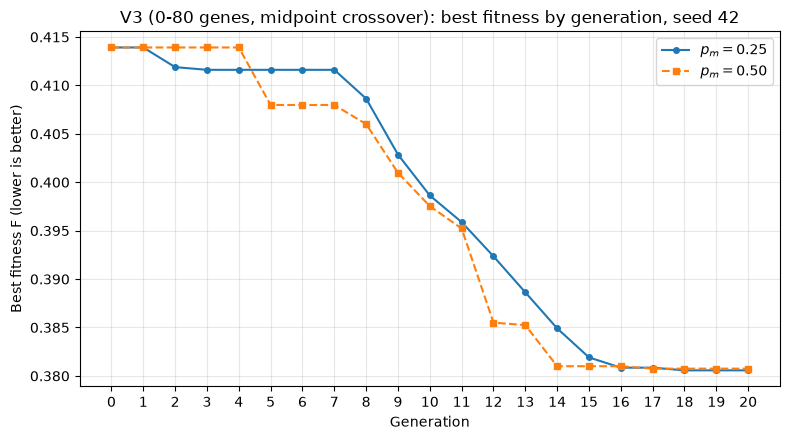

p_m = 0.25 best F by generation: [0.41392, 0.41392, 0.41189, 0.41161, 0.41161, 0.41161, 0.41161, 0.41161, 0.40863, 0.40286, 0.39863, 0.39588, 0.39235, 0.38863, 0.38491, 0.38191, 0.38085, 0.38085, 0.38057, 0.38057, 0.38057]
p_m = 0.50 best F by generation: [0.41392, 0.41392, 0.41392, 0.41392, 0.41392, 0.40798, 0.40798, 0.40798, 0.40601, 0.40098, 0.39753, 0.39523, 0.3855, 0.38525, 0.381, 0.381, 0.381, 0.38075, 0.38075, 0.38075, 0.38075]


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
gens = range(len(final_baseline["history"]))
ax.plot(gens, final_baseline["history"], marker="o", markersize=4, linestyle="-", label=r"$p_m = 0.25$")
ax.plot(gens, final_variant["history"], marker="s", markersize=4, linestyle="--", label=r"$p_m = 0.50$")
ax.set_xlabel("Generation")
ax.set_ylabel("Best fitness F (lower is better)")
ax.set_title("V3 (0-80 genes, midpoint crossover): best fitness by generation, seed 42")
ax.set_xticks(list(gens))
ax.grid(True, alpha=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

for label, res in [("p_m = 0.25", final_baseline), ("p_m = 0.50", final_variant)]:
    print(label, "best F by generation:", np.round(res["history"], 5).tolist())

### C2. We compare $p_m=0.25$ and $p_m=0.50$

| Condition | Value in both runs |
|:--|:--|
| Version and operators | V3: same code, tournament of two, midpoint crossover, $\pm1$ mutation, one elite |
| Population / generations | 20 individuals / 20 generations |
| Seed and initial population | 42; both runs start from the generation 0 traced above |
| Data, domains, capacity, fitness | March 2025 monthly demands, $\{0,\ldots,80\}$ ($\{0,\ldots,60\}$ Cedetec), $C=1410$ m$^3$, tolerance $10^{-8}$ m$^3$ |
| **Only change** | **Per-gene mutation probability $p_m$: 0.25 versus 0.50** |

| | $p_m=0.25$ | $p_m=0.50$ |
|:--|--:|--:|
| Best chromosome $k$ | $(63,68,44,64)$ | $(63,62,44,68)$ |
| Treated water $T$ (m$^3$) | 1409.942 | 1409.542 |
| Potable water $P$ (m$^3$) | 866.268 | 866.668 |
| Excess capacity $E$ (m$^3$) | 0 | 0 |
| Unused capacity $C-T$ (m$^3$) | 0.058 | 0.458 |
| Feasible | Yes | Yes |
| Best fitness $F$ | 0.38057455 | 0.38075028 |
| First improvement / last improvement | generation 2 / 18 | generation 5 / 17 |

**Trajectories.** Both curves start at $F=0.41392$, the elite of the traced generation 0. With $p_m=0.25$ small improvements appear in generations 2 and 3; then the curve is flat until generation 7, improves in every generation from 8 to 16, and reaches its final value in generation 18. With $p_m=0.50$ the curve stays flat until generation 5, improves mostly between generations 8 and 14, and reaches its final value in generation 17. So $p_m=0.50$ is ahead from generation 5 to 15; $p_m=0.25$ passes it in generation 16 and finishes ahead. Because of elitism neither curve ever goes up; a flat segment means that no child beat the elite, not that the search is finished.

Both runs show many small steps rather than a few big jumps. That is what we expect from V3: midpoint crossover places children between their parents, and mutation moves a gene by only one percentage point, so the best $T$ climbs towards $C$ gradually.

**Difference.** With seed 42, $p_m=0.25$ ends slightly better: $\Delta F=0.00018$, which is 0.40 m$^3$ of potable water over March 2025 (0.02% of the monthly demand). With one seed per configuration we can't say that one probability is better in general; a higher $p_m$ adds more random steps per child, which can help escape plateaus or disturb good children, and seed 42 only shows one outcome. We would need several seeds to make a general claim, and neither run is guaranteed to be the global optimum.

### C3. Physical interpretation

**Allocation by building.** All values are monthly totals for March 2025, in m$^3$:

| Building | $D_i$ | Limit | $p_m=0.25$: $x_i$ | $T_i$ | $P_i$ | $p_m=0.50$: $x_i$ | $T_i$ | $P_i$ |
|:--|--:|--:|--:|--:|--:|--:|--:|--:|
| Aulas 1 | 847.00 | 80% | 63% | 533.610 | 313.390 | 63% | 533.610 | 313.390 |
| Biblioteca | 462.00 | 80% | 68% | 314.160 | 147.840 | 62% | 286.440 | 175.560 |
| Cedetec | 284.21 | 60% | 44% | 125.052 | 159.158 | 44% | 125.052 | 159.158 |
| Aulas 2 | 683.00 | 80% | 64% | 437.120 | 245.880 | 68% | 464.440 | 218.560 |
| **Total** | **2276.21** | | | **1409.942** | **866.268** | | **1409.542** | **866.668** |

In every row $T_i+P_i=D_i$. The two solutions agree on Aulas 1 (63%) and Cedetec (44%) and differ on Biblioteca and Aulas 2: $p_m=0.50$ gives Biblioteca 27.720 m$^3$ less treated water and Aulas 2 27.320 m$^3$ more, so the total is almost the same. No building reaches its reuse limit; midpoint crossover keeps genes near the middle of their parents, so the allocations are spread evenly instead of pushing some buildings to 80%.

**Capacity is the binding constraint.** If every building used its maximum reuse, the campus would need $T=1764.126$ m$^3$ of treated water, 354.126 m$^3$ more than the plant can supply. So the reuse limits never bind at the optimum; the capacity does. The best any allocation can do is $T=C=1410$ m$^3$, which leaves $P=2276.21-1410=866.21$ m$^3$ of potable water ($F=0.380549$). Both runs are within 0.5 m$^3$ of that bound, and together they cover about 61.9% of the monthly demand with treated water, compared with 60% in our hand calculation $(60,60,60,60)$, which left 44.274 m$^3$ of capacity unused.

**Why the split between buildings is arbitrary.** For a feasible candidate $F = 1 - T/\sum_i D_i$, so the fitness only depends on the total $T$, not on which building receives it. Many chromosomes reach $T\approx C$ (145 reach it exactly on the 0-80 grid), and the GA has no reason to prefer one of them. The differences between the two allocations are therefore an outcome of the random search, not a recommendation to give more treated water to one building.

**Assumptions and scope.**

- The demands are observed monthly totals for March 2025; the results describe this one month and don't account for variation within the month (daily or hourly peaks) or between months.
- The capacity $C=1410$ m$^3$ and the reuse limits (80%, 80%, 60%, 80%) are teaching assumptions, not confirmed plant data. Since the capacity is binding, a different $C$ would change the solution directly.
- The model treats all buildings the same: it doesn't include piping or pumping costs, distance from the plant, storage, water quality requirements, or which uses inside each building can take treated water.
- Reuse levels are discrete in steps of 1%. Differences of a fraction of a cubic metre are far below the precision of monthly records.
- This is a monthly volumetric teaching model; it does not establish a validated hydraulic or sanitary recommendation for the plant.

## 11. We check reproduction

We repeat the Final $p_m=0.25$ run with the same version and seed and check that the genes and the history match. We also restart the kernel and run the notebook from top to bottom, to make sure the results don't depend on cells we executed earlier. Note that this is a technical check, not a third experimental configuration. The last assertions check elitism: the best fitness never goes up from one generation to the next, in either run.

In [16]:
repeated = run_version(FINAL_VERSION, **CONFIG_FINAL, mutation_probability=0.25)
np.testing.assert_array_equal(final_baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(final_baseline["history"], repeated["history"])
assert np.all(np.diff(final_baseline["history"]) <= 1e-12)
assert np.all(np.diff(final_variant["history"]) <= 1e-12)
print("Reproduction and elitism checked.")

Reproduction and elitism checked.


## 12. Keep evidence in the same notebook

- **Research (15%)**: A1 formulation and assumptions (60/100); A2 hand calculation and comparison with the evaluator (40/100).
- **Development (15%)**: B1 functional cycle and justified substantive modification of one operator (70/100); B2 reproducibility and controlled baseline/variant comparison (30/100). Use $p_m=0.25$ for both versions.
- **Final (30%)**: C1 explanation of one generation (40/100); C2 same-code comparison of mutation probabilities 0.25/0.50 and its plot (35/100); C3 physical interpretation and model limitations (25/100).

For Final, retain earlier sections and add your team's explanation. Identify the supplied baseline and any team changes. If you still have only the baseline, identify it as unmodified and complete the Final analysis; the Development penalty will not be applied again. Keep the supplied environment files beside the notebook. The written team code examination will contribute 10% and the individual article examination will contribute 30%. Consult the [guide](challenge_guide_planta_fisica.pdf) and the detailed instructions in Canvas for performance levels and dates.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.